# 05. Full Fine-tuning Baseline

## 실험 목적

ImageNet 사전학습 가중치를 적용한 ResNet18의 전체
파라미터를 학습하여 행동 분류 모델의 기준선을 구축한다.

- 사전학습된 백본과 새롭게 초기화된 FC Layer에
  서로 다른 학습률을 적용한다.
- 백본의 기존 특징을 보존하면서 행동 분류 데이터에
  적합하도록 전체 가중치를 조정한다.
- 기존 Scratch 및 Feature Extraction 기준선과
  분류 성능, 수렴 속도, 과적합 여부, 학습 효율을 비교한다.
- Validation Macro F1-score를 기준으로 최적 모델을 선정한다.

기존 데이터 분할, 전처리 및 공통 학습·평가 모듈을
유지하며, Test 데이터는 최종 모델 선정 이후 평가한다.

## 1. 라이브러리 및 공통 모듈 Import

기존 공통 전처리, 학습, 평가 및 시각화 모듈을
재사용하여 실험 간 일관성을 유지한다.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import resnet18, ResNet18_Weights

# 프로젝트 루트 경로 설정
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    set_seed,
    get_dataloaders,
    SEED,
    IMAGE_SIZE,
    BATCH_SIZE,
    NUM_CLASSES
)

from src.training import (
    fit,
    save_training_results
)

from src.evaluation import (
    CLASS_NAMES,
    load_best_model,
    evaluate_model,
    analyze_class_performance,
    save_predictions,
    save_evaluation_results
)

from src.visualization import (
    plot_learning_curves,
    plot_class_metrics,
    plot_confusion_matrix
)

## 2. 실험 설정 및 경로 정의

기존 기준선과 동일한 데이터 분할, 전처리 및 공통 학습 조건을 유지한다.

Full Fine-tuning에서는 사전학습된 백본과 새롭게 초기화된
FC Layer에 서로 다른 학습률을 적용한다.

- Backbone Learning Rate: 0.0001
- FC Learning Rate: 0.001
- 전체 파라미터 학습
- BatchNorm 이동 통계 업데이트 허용

실험 결과는 기존 기준선과 구분하여 별도로 저장한다.

In [3]:
# 실험 설정
EXPERIMENT_NAME = "fine_tuning_baseline"

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1

EPOCHS = 30
BACKBONE_LR = 0.0001
FC_LR = 0.001
WEIGHT_DECAY = 0

FREEZE_BACKBONE_BN = False

# 학습 환경 설정
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Random Seed 고정
set_seed(SEED)

In [4]:
# 결과 저장 경로
OUTPUT_DIR = PROJECT_ROOT / "outputs"
RESULT_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = PROJECT_ROOT / "figures"

# 디렉토리 생성
for directory in [OUTPUT_DIR, RESULT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# 최적 모델 저장 경로
CHECKPOINT_PATH = OUTPUT_DIR / f"{EXPERIMENT_NAME}_best.pth"

In [5]:
print(f"Experiment: {EXPERIMENT_NAME}")
print(f"Pretrained Weights: {WEIGHTS.name}")
print(f"Device: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Version: {torch.version.cuda}")

print("-" * 50)

print(f"Image Size: {IMAGE_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Num Classes: {NUM_CLASSES}")
print(f"Seed: {SEED}")
print(f"Epochs: {EPOCHS}")
print(f"Backbone LR: {BACKBONE_LR}")
print(f"FC LR: {FC_LR}")
print(f"Weight Decay: {WEIGHT_DECAY}")
print(f"Freeze Backbone BN: {FREEZE_BACKBONE_BN}")

print("-" * 50)

print(f"Checkpoint Path: {CHECKPOINT_PATH}")

Experiment: fine_tuning_baseline
Pretrained Weights: IMAGENET1K_V1
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
PyTorch Version: 2.10.0+cu128
CUDA Version: 12.8
--------------------------------------------------
Image Size: 224
Batch Size: 32
Num Classes: 8
Seed: 42
Epochs: 30
Backbone LR: 0.0001
FC LR: 0.001
Weight Decay: 0
Freeze Backbone BN: False
--------------------------------------------------
Checkpoint Path: c:\Users\yunha\human-action-classification\outputs\fine_tuning_baseline_best.pth


## 3. DataLoader 구성

공통 전처리 모듈을 활용하여 Train, Validation, Test
DataLoader를 구성한다.

- 기존 데이터 분할 및 전처리 조건 유지
- 입력 이미지 크기: 224 × 224
- Batch Size: 32
- Train 데이터에만 Shuffle 적용
- 데이터 증강 미적용

모델 학습에는 Train, 모델 선택 및 성능 평가에는
Validation 데이터를 사용한다.
Test 데이터는 최종 모델 선정 이후 평가한다.

In [9]:
set_seed(SEED)

train_loader, val_loader, test_loader = get_dataloaders()

loader_info = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [
        len(train_loader.dataset),
        len(val_loader.dataset),
        len(test_loader.dataset)
    ],
    "Batches": [
        len(train_loader),
        len(val_loader),
        len(test_loader)
    ]
})

display(loader_info)

images, labels = next(iter(train_loader))

print(f"Image Shape: {images.shape}")
print(f"Label Shape: {labels.shape}")
print(f"Image Dtype: {images.dtype}")
print(f"Label Dtype: {labels.dtype}")

,Split,Images,Batches
0,Train,640,20
1,Validation,160,5
2,Test,1231,39


Image Shape: torch.Size([32, 3, 224, 224])
Label Shape: torch.Size([32])
Image Dtype: torch.float32
Label Dtype: torch.int64


## 4. 사전학습 모델 생성 및 전체 파라미터 학습 설정

ImageNet 사전학습 가중치를 적용한 ResNet18을 생성하고,
기존 FC Layer를 8개 클래스 분류기로 교체한다.

Feature Extraction과 달리 백본을 동결하지 않고
전체 파라미터를 학습 대상으로 설정한다.

- Pretrained Weights: IMAGENET1K_V1
- Output Classes: 8
- Trainable Layers: All
- BatchNorm 이동 통계 업데이트 허용

기존 Feature Extraction의 Checkpoint를 사용하지 않고
ImageNet 사전학습 가중치에서 독립적으로 학습을 시작한다.

In [10]:
set_seed(SEED)

# ImageNet 사전학습 모델 생성
model = resnet18(weights=WEIGHTS)

# FC Layer 교체
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

# 전체 파라미터 학습 허용
for param in model.parameters():
    param.requires_grad = True

# GPU 이동
model = model.to(DEVICE)

print(model.fc)

Linear(in_features=512, out_features=8, bias=True)


In [11]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters: {frozen_params:,}")
print(f"Trainable Ratio: {trainable_params / total_params:.2%}")

Total Parameters: 11,180,616
Trainable Parameters: 11,180,616
Frozen Parameters: 0
Trainable Ratio: 100.00%


In [12]:
# Backbone 파라미터
backbone_params = [
    param
    for name, param in model.named_parameters()
    if not name.startswith("fc.")
]

# FC Layer 파라미터
fc_params = list(model.fc.parameters())

# 그룹별 파라미터 수 확인
backbone_count = sum(p.numel() for p in backbone_params)
fc_count = sum(p.numel() for p in fc_params)

param_info = pd.DataFrame({
    "Parameter Group": ["Backbone", "FC", "Total"],
    "Parameters": [
        backbone_count,
        fc_count,
        backbone_count + fc_count
    ]
})

display(param_info)

,Parameter Group,Parameters
0,Backbone,11176512
1,FC,4104
2,Total,11180616


In [13]:
# 모든 파라미터가 학습 가능한지 확인
assert all(p.requires_grad for p in model.parameters())

# 파라미터 그룹 간 중복 여부 확인
backbone_ids = {id(p) for p in backbone_params}
fc_ids = {id(p) for p in fc_params}

assert backbone_ids.isdisjoint(fc_ids)

# 누락된 파라미터가 없는지 확인
model_ids = {id(p) for p in model.parameters()}

assert backbone_ids | fc_ids == model_ids

print("Parameter group validation passed.")

Parameter group validation passed.


## 5. Loss 및 Optimizer 설정

기존 기준선과 동일하게 CrossEntropyLoss와 Adam을 사용한다.

Full Fine-tuning에서는 Parameter Group을 활용하여
사전학습된 백본과 새롭게 초기화된 FC Layer에
서로 다른 학습률을 적용한다.

- Loss: CrossEntropyLoss
- Optimizer: Adam
- Backbone Learning Rate: 0.0001
- FC Learning Rate: 0.001
- Weight Decay: 0
- Scheduler: None

사전학습된 특징의 급격한 변화를 완화하면서
새로운 분류기는 상대적으로 빠르게 학습하도록 구성한다.

In [16]:
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    [
        {"params": backbone_params, "lr": BACKBONE_LR},
        {"params": fc_params, "lr": FC_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

optimizer_info = pd.DataFrame([
    {
        "Parameter Group": group_name,
        "Learning Rate": group["lr"],
        "Weight Decay": group["weight_decay"],
        "Parameters": sum(
            p.numel() for p in group["params"]
        )
    }
    for group_name, group in zip(
        ["Backbone", "FC"],
        optimizer.param_groups
    )
])

display(optimizer_info)

,Parameter Group,Learning Rate,Weight Decay,Parameters
0,Backbone,0.0001,0,11176512
1,FC,0.0010,0,4104


In [17]:
# Parameter Group 개수 확인
assert len(optimizer.param_groups) == 2

# 그룹별 학습률 확인
assert optimizer.param_groups[0]["lr"] == BACKBONE_LR
assert optimizer.param_groups[1]["lr"] == FC_LR

# 전체 학습 가능 파라미터가 Optimizer에 포함되었는지 확인
optimizer_param_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

trainable_param_ids = {
    id(p)
    for p in model.parameters()
    if p.requires_grad
}

assert optimizer_param_ids == trainable_param_ids

print("Optimizer validation passed.")

Optimizer validation passed.


## 6. 모델 학습 및 결과 저장

공통 학습 함수 fit()을 활용하여 Full Fine-tuning 모델을 학습한다.

- 전체 학습 Epoch: 30
- Backbone Learning Rate: 0.0001
- FC Learning Rate: 0.001
- BatchNorm 이동 통계 업데이트 허용
- Checkpoint 선정 기준: Validation Macro F1-score

Epoch별 Train/Validation Loss, Accuracy, Macro F1-score
및 학습 시간을 기록한다.

Validation Macro F1-score가 가장 높은 모델을 저장하고,
학습 기록과 실험 설정을 CSV 파일로 저장한다.

In [18]:
history_df, total_training_time = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    epochs=EPOCHS,
    checkpoint_path=CHECKPOINT_PATH,
    freeze_backbone_bn=FREEZE_BACKBONE_BN
)

Epoch [01/30] | Train Loss: 1.1159 | Train Acc: 0.6438 | Train F1: 0.6437 | Val Loss: 0.5870 | Val Acc: 0.8125 | Val F1: 0.8156 | Time: 4.02s | Best Model Saved
Epoch [02/30] | Train Loss: 0.1613 | Train Acc: 0.9672 | Train F1: 0.9672 | Val Loss: 0.4991 | Val Acc: 0.8562 | Val F1: 0.8540 | Time: 3.17s | Best Model Saved
Epoch [03/30] | Train Loss: 0.0395 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.4599 | Val Acc: 0.8562 | Val F1: 0.8532 | Time: 3.15s
Epoch [04/30] | Train Loss: 0.0162 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.4400 | Val Acc: 0.8625 | Val F1: 0.8587 | Time: 3.11s | Best Model Saved
Epoch [05/30] | Train Loss: 0.0082 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.4396 | Val Acc: 0.8625 | Val F1: 0.8593 | Time: 3.10s | Best Model Saved
Epoch [06/30] | Train Loss: 0.0067 | Train Acc: 1.0000 | Train F1: 1.0000 | Val Loss: 0.4449 | Val Acc: 0.8562 | Val F1: 0.8527 | Time: 3.09s
Epoch [07/30] | Train Loss: 0.0046 | Train Acc: 1.0000 | Train F1: 1.000

In [19]:
display(history_df.head())
display(history_df.tail())

print(f"Total Training Time: {total_training_time:.2f} sec")
print(f"Mean Epoch Time: {history_df['epoch_time_sec'].mean():.2f} sec")

,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
0,1,1.115927,0.643750,0.643739,0.587005,0.81250,0.815609,4.017306
1,2,0.161295,0.967187,0.967233,0.499098,0.85625,0.853956,3.165618
2,3,0.039505,1.000000,1.000000,0.459869,0.85625,0.853156,3.150442
3,4,0.016199,1.000000,1.000000,0.439979,0.86250,0.858670,3.113047
4,5,0.008175,1.000000,1.000000,0.439640,0.86250,0.859318,3.098445


,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
25,26,0.000686,1.0,1.0,0.467089,0.89375,0.891342,3.307618
26,27,0.000653,1.0,1.0,0.471658,0.87500,0.872944,3.286449
27,28,0.000422,1.0,1.0,0.473531,0.87500,0.872279,3.336354
28,29,0.000586,1.0,1.0,0.475043,0.87500,0.872453,3.282699
29,30,0.000554,1.0,1.0,0.481063,0.87500,0.872908,3.312682


Total Training Time: 97.81 sec
Mean Epoch Time: 3.25 sec


In [20]:
best_idx = history_df["val_f1"].idxmax()
best_epoch_result = history_df.loc[[best_idx]]

display(best_epoch_result)

,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
25,26,0.000686,1.0,1.0,0.467089,0.89375,0.891342,3.307618


In [21]:
scratch_summary = pd.read_csv(
    RESULT_DIR / "scratch_baseline_summary.csv"
)

feature_summary = pd.read_csv(
    RESULT_DIR / "feature_extraction_baseline_summary.csv"
)

print("Scratch Summary Columns")
print(scratch_summary.columns.tolist())

print("\nFeature Extraction Summary Columns")
print(feature_summary.columns.tolist())

Scratch Summary Columns
['experiment_name', 'model', 'training_strategy', 'pretrained_weights', 'train_samples', 'val_samples', 'num_classes', 'image_size', 'batch_size', 'augmentation', 'seed', 'optimizer', 'loss_function', 'learning_rate', 'weight_decay', 'epochs', 'lr_scheduler', 'total_params', 'trainable_params', 'best_epoch', 'best_train_loss', 'best_train_accuracy', 'best_train_f1', 'best_val_loss', 'best_val_accuracy', 'best_val_f1', 'mean_epoch_time_sec', 'total_training_time_sec', 'device', 'gpu_name', 'torch_version', 'cuda_version']

Feature Extraction Summary Columns
['experiment_name', 'model_name', 'training_strategy', 'pretrained_weights', 'trainable_layers', 'freeze_backbone_bn', 'optimizer', 'learning_rate', 'weight_decay', 'loss_function', 'batch_size', 'epochs', 'seed', 'image_size', 'num_classes', 'scheduler', 'augmentation', 'checkpoint_metric', 'total_params', 'trainable_params', 'best_epoch', 'best_train_loss', 'best_train_accuracy', 'best_train_f1', 'best_val_l

In [22]:
experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "model_name": "ResNet18",
    "training_strategy": "full_fine_tuning",
    "pretrained_weights": WEIGHTS.name,
    "trainable_layers": "all",
    "freeze_backbone_bn": FREEZE_BACKBONE_BN,
    "optimizer": type(optimizer).__name__,
    "learning_rate": None,
    "backbone_lr": BACKBONE_LR,
    "fc_lr": FC_LR,
    "weight_decay": WEIGHT_DECAY,
    "loss_function": type(criterion).__name__,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "scheduler": "None",
    "augmentation": "None",
    "checkpoint_metric": "val_f1",
}

In [23]:
summary_df = save_training_results(
    history_df=history_df,
    total_training_time=total_training_time,
    experiment_config=experiment_config,
    model=model,
    device=DEVICE,
    result_dir=RESULT_DIR
)

display(summary_df.T)

History Saved: c:\Users\yunha\human-action-classification\results\fine_tuning_baseline_history.csv
Summary Saved: c:\Users\yunha\human-action-classification\results\fine_tuning_baseline_summary.csv


,0
experiment_name,fine_tuning_baseline
model_name,ResNet18
training_strategy,full_fine_tuning
pretrained_weights,IMAGENET1K_V1
trainable_layers,all
freeze_backbone_bn,False
optimizer,Adam
learning_rate,None
backbone_lr,0.0001
fc_lr,0.001


In [24]:
saved_files = [
    CHECKPOINT_PATH,
    RESULT_DIR / f"{EXPERIMENT_NAME}_history.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_summary.csv"
]

for file in saved_files:
    print(f"{file.name}: {file.exists()}")

fine_tuning_baseline_best.pth: True
fine_tuning_baseline_history.csv: True
fine_tuning_baseline_summary.csv: True


## 7. 최적 모델 평가 및 시각화

Validation Macro F1-score가 가장 높은 Epoch의
Checkpoint를 불러와 Validation 데이터에서 성능을 평가한다.

- Accuracy, Macro Precision, Recall, F1-score
- Train/Validation 학습 곡선
- 클래스별 Precision, Recall, F1-score
- Confusion Matrix 및 주요 혼동 클래스
- 이미지별 예측 결과 및 Confidence

평가 결과와 시각화 자료를 저장하여 이후 학습 전략 비교
및 오류 분석에 활용한다.

Test 데이터는 최종 모델 선정 전까지 평가하지 않는다.

In [25]:
best_model, checkpoint = load_best_model(
    model=model,
    checkpoint_path=CHECKPOINT_PATH,
    device=DEVICE
)

best_epoch = int(best_epoch_result["epoch"].iloc[0])

print(f"Best Epoch: {best_epoch}")

===== Best Checkpoint Loaded =====
Best Epoch: 26
Validation Loss: 0.4671
Validation Accuracy: 0.8938
Validation Macro F1: 0.8913
Best Epoch: 26


In [26]:
evaluation = evaluate_model(
    model=best_model,
    dataloader=val_loader,
    criterion=criterion,
    device=DEVICE
)

display(pd.DataFrame([evaluation["metrics"]]))

,loss,accuracy,macro_precision,macro_recall,macro_f1
0,0.467089,0.89375,0.89381,0.89375,0.891342


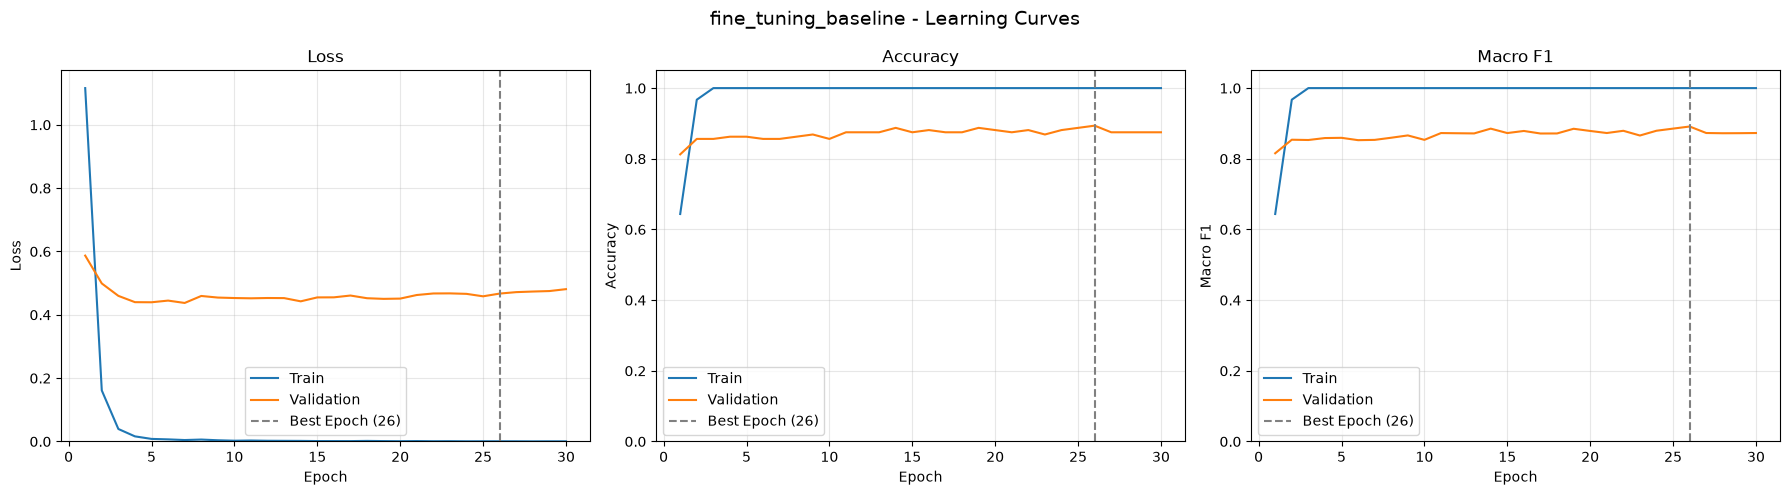

Learning Curves Saved: c:\Users\yunha\human-action-classification\figures\fine_tuning_baseline_learning_curves.png


In [28]:
plot_learning_curves(
    history_df=history_df,
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR
)

In [29]:
class_analysis = analyze_class_performance(
    y_true=evaluation["y_true"],
    y_pred=evaluation["y_pred"],
    class_names=CLASS_NAMES
)

display(class_analysis["report_df"])

,precision,recall,f1-score,support
Climbing,0.909091,1.00000,0.952381,20.00000
Jumping,0.850000,0.85000,0.850000,20.00000
Riding Bike,0.869565,1.00000,0.930233,20.00000
Riding Horse,0.944444,0.85000,0.894737,20.00000
Rowing Boat,0.952381,1.00000,0.975610,20.00000
Running,0.875000,0.70000,0.777778,20.00000
Shooting Arrow,0.900000,0.90000,0.900000,20.00000
Throwing Frisbee,0.850000,0.85000,0.850000,20.00000
accuracy,0.893750,0.89375,0.893750,0.89375
macro avg,0.893810,0.89375,0.891342,160.00000


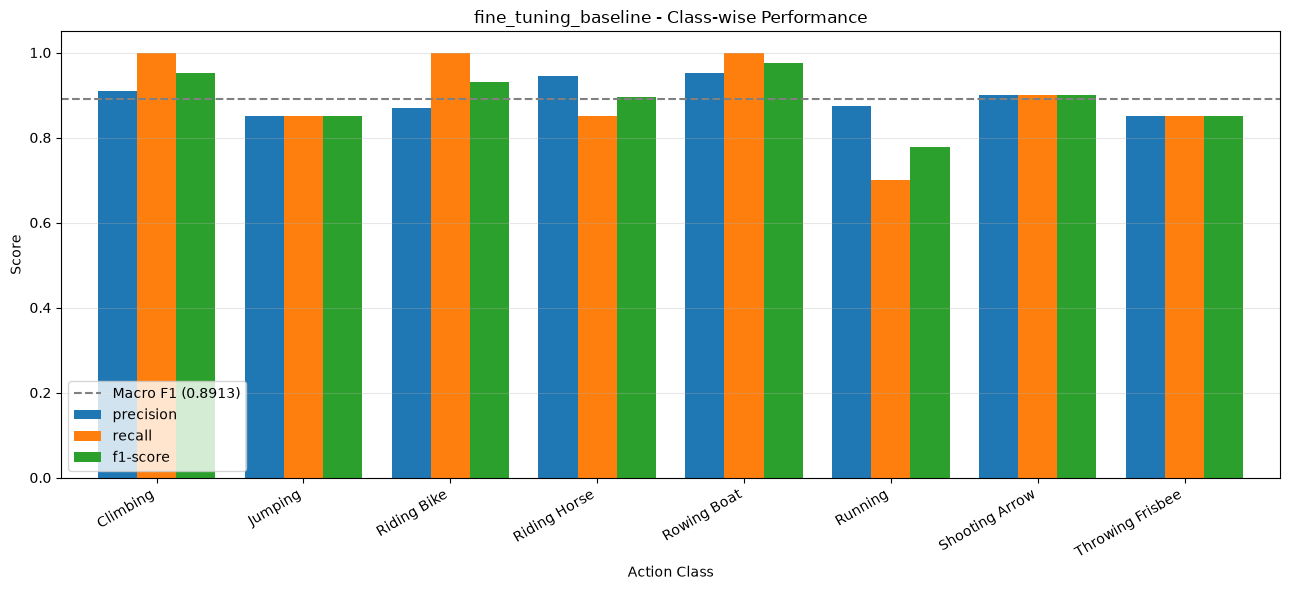

Class Metrics Saved: c:\Users\yunha\human-action-classification\figures\fine_tuning_baseline_class_metrics.png


In [30]:
plot_class_metrics(
    class_report_df=class_analysis["class_report_df"],
    macro_f1=best_epoch_result["val_f1"].iloc[0],
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR
)

,Climbing,Jumping,Riding Bike,Riding Horse,Rowing Boat,Running,Shooting Arrow,Throwing Frisbee
Climbing,20,0,0,0,0,0,0,0
Jumping,0,17,0,0,0,1,1,1
Riding Bike,0,0,20,0,0,0,0,0
Riding Horse,0,0,2,17,1,0,0,0
Rowing Boat,0,0,0,0,20,0,0,0
Running,2,0,1,1,0,14,1,1
Shooting Arrow,0,1,0,0,0,0,18,1
Throwing Frisbee,0,2,0,0,0,1,0,17


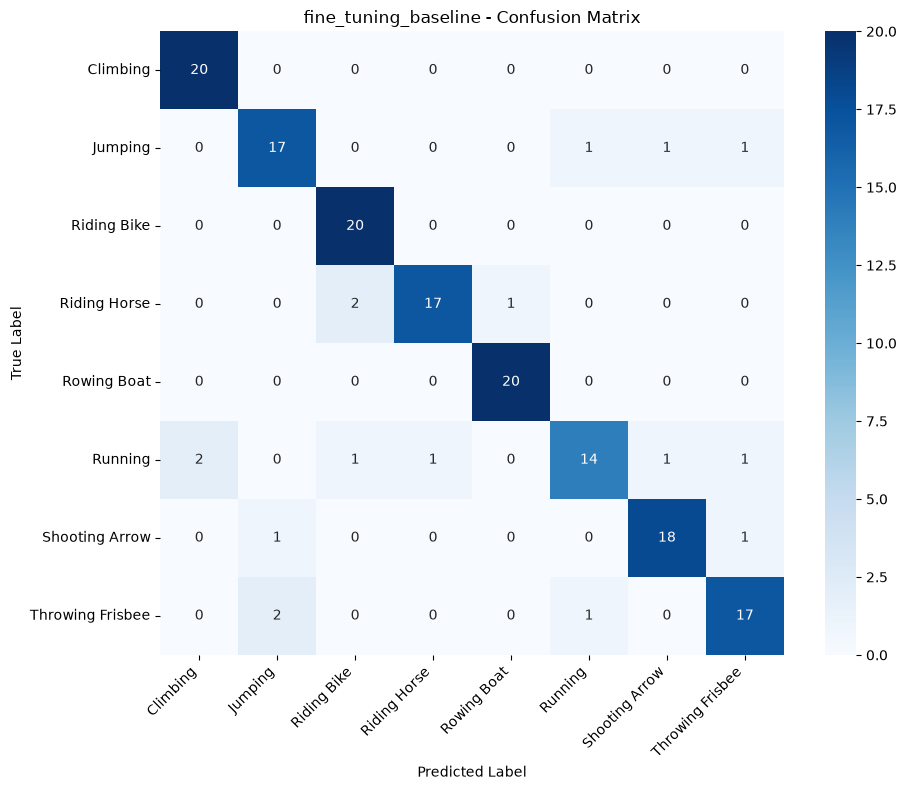

Confusion Matrix Saved: c:\Users\yunha\human-action-classification\figures\fine_tuning_baseline_confusion_matrix.png


In [31]:
display(class_analysis["cm_df"])

plot_confusion_matrix(
    cm_df=class_analysis["cm_df"],
    experiment_name=EXPERIMENT_NAME,
    figure_dir=FIGURE_DIR,
    normalize=False,
    vmax=20
)

In [32]:
display(class_analysis["confusion_pairs_df"])

,true_class,predicted_class,count
0,Running,Climbing,2
1,Riding Horse,Riding Bike,2
2,Throwing Frisbee,Jumping,2
3,Jumping,Shooting Arrow,1
4,Jumping,Throwing Frisbee,1
5,Jumping,Running,1
6,Riding Horse,Rowing Boat,1
7,Running,Riding Bike,1
8,Running,Shooting Arrow,1
9,Running,Riding Horse,1


In [33]:
save_predictions(
    evaluation=evaluation,
    metadata_df=val_loader.dataset.df,
    dataloader=val_loader,
    experiment_name=EXPERIMENT_NAME,
    result_dir=RESULT_DIR
)

Predictions Saved: c:\Users\yunha\human-action-classification\results\fine_tuning_baseline_predictions.csv


,image_id,image_path,split,target_id,class_name,class_name_ko,source_filename,original_split,group_id,width,...,confidence,is_correct,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7
0,s40_0216b979b86639cf5693,images/val/s40_0216b979b86639cf5693.jpg,val,5,running,달리기,running_043.jpg,train,group_s40_0216b979b86639cf5693,903,...,0.909099,True,3.286648e-04,1.393824e-02,0.000570,3.045872e-02,9.002097e-03,9.090990e-01,8.878618e-05,3.651464e-02
1,s40_029af1e3d7b9729f517c,images/val/s40_029af1e3d7b9729f517c.jpg,val,7,throwing_frisby,프리스비 던지기,throwing_frisby_138.jpg,train,group_s40_029af1e3d7b9729f517c,200,...,0.988248,False,9.269082e-05,4.821880e-03,0.000353,1.116050e-04,6.527363e-05,9.882483e-01,2.375194e-04,6.069278e-03
2,s40_02d39f1725b5d618f932,images/val/s40_02d39f1725b5d618f932.jpg,val,2,riding_a_bike,자전거 타기,riding_a_bike_030.jpg,train,group_s40_02d39f1725b5d618f932,300,...,0.999997,True,2.029664e-07,9.832534e-07,0.999997,3.177589e-07,6.161747e-08,3.108551e-07,6.472213e-07,3.416465e-08
3,s40_0318ccfcfa1ee7a6bd3a,images/val/s40_0318ccfcfa1ee7a6bd3a.jpg,val,0,climbing,등반,climbing_092.jpg,train,group_s40_0318ccfcfa1ee7a6bd3a,400,...,0.999861,True,9.998614e-01,1.650946e-05,0.000028,1.120658e-05,1.247629e-05,1.575159e-05,4.856715e-05,6.619740e-06
4,s40_036fd8dc9a335330714a,images/val/s40_036fd8dc9a335330714a.jpg,val,6,shooting_an_arrow,활쏘기,shooting_an_arrow_174.jpg,train,group_s40_036fd8dc9a335330714a,300,...,0.999978,True,1.366590e-06,7.562904e-06,0.000002,3.108232e-06,5.914153e-06,7.223882e-07,9.999781e-01,9.604413e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,s40_f73e1058a4cdef838618,images/val/s40_f73e1058a4cdef838618.jpg,val,6,shooting_an_arrow,활쏘기,shooting_an_arrow_123.jpg,train,group_s40_f73e1058a4cdef838618,400,...,0.999844,True,9.014822e-06,8.593239e-06,0.000016,3.850464e-06,4.725071e-06,3.083808e-05,9.998442e-01,8.331478e-05
156,s40_f78b44150d68a72bd13d,images/val/s40_f78b44150d68a72bd13d.jpg,val,1,jumping,점프,jumping_192.jpg,train,group_s40_f78b44150d68a72bd13d,500,...,0.944809,True,2.557722e-03,9.448094e-01,0.000327,4.533487e-05,5.063167e-04,4.963030e-02,8.252544e-04,1.298554e-03
157,s40_f96a52bb4bc0adaef957,images/val/s40_f96a52bb4bc0adaef957.jpg,val,5,running,달리기,running_229.jpg,train,group_s40_f96a52bb4bc0adaef957,300,...,0.994606,True,3.551405e-05,2.420062e-04,0.002429,9.452322e-05,2.639835e-05,9.946058e-01,2.089362e-04,2.357274e-03
158,s40_fb35fe82871c1fb2e763,images/val/s40_fb35fe82871c1fb2e763.jpg,val,4,rowing_a_boat,보트 노 젓기,rowing_a_boat_088.jpg,train,group_s40_fb35fe82871c1fb2e763,306,...,0.999945,True,3.666531e-06,6.539086e-06,0.000007,5.069250e-06,9.999450e-01,2.831238e-05,1.045985e-06,3.054912e-06


In [34]:
predictions_df = pd.read_csv(
    RESULT_DIR / f"{EXPERIMENT_NAME}_predictions.csv"
)

display(predictions_df.head())

print(f"Total Predictions: {len(predictions_df)}")
print(f"Correct: {predictions_df['is_correct'].sum()}")
print(f"Incorrect: {(~predictions_df['is_correct']).sum()}")

,image_id,image_path,split,target_id,class_name,class_name_ko,source_filename,original_split,group_id,width,...,confidence,is_correct,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7
0,s40_0216b979b86639cf5693,images/val/s40_0216b979b86639cf5693.jpg,val,5,running,달리기,running_043.jpg,train,group_s40_0216b979b86639cf5693,903,...,0.909099,True,3.286648e-04,1.393824e-02,0.000570,3.045872e-02,9.002097e-03,9.090990e-01,8.878618e-05,3.651464e-02
1,s40_029af1e3d7b9729f517c,images/val/s40_029af1e3d7b9729f517c.jpg,val,7,throwing_frisby,프리스비 던지기,throwing_frisby_138.jpg,train,group_s40_029af1e3d7b9729f517c,200,...,0.988248,False,9.269082e-05,4.821880e-03,0.000353,1.116050e-04,6.527363e-05,9.882483e-01,2.375194e-04,6.069278e-03
2,s40_02d39f1725b5d618f932,images/val/s40_02d39f1725b5d618f932.jpg,val,2,riding_a_bike,자전거 타기,riding_a_bike_030.jpg,train,group_s40_02d39f1725b5d618f932,300,...,0.999997,True,2.029664e-07,9.832534e-07,0.999997,3.177589e-07,6.161747e-08,3.108551e-07,6.472213e-07,3.416465e-08
3,s40_0318ccfcfa1ee7a6bd3a,images/val/s40_0318ccfcfa1ee7a6bd3a.jpg,val,0,climbing,등반,climbing_092.jpg,train,group_s40_0318ccfcfa1ee7a6bd3a,400,...,0.999861,True,9.998614e-01,1.650946e-05,0.000028,1.120658e-05,1.247629e-05,1.575159e-05,4.856715e-05,6.619740e-06
4,s40_036fd8dc9a335330714a,images/val/s40_036fd8dc9a335330714a.jpg,val,6,shooting_an_arrow,활쏘기,shooting_an_arrow_174.jpg,train,group_s40_036fd8dc9a335330714a,300,...,0.999978,True,1.366590e-06,7.562904e-06,0.000002,3.108232e-06,5.914153e-06,7.223882e-07,9.999781e-01,9.604413e-07


Total Predictions: 160
Correct: 143
Incorrect: 17


In [35]:
save_evaluation_results(
    evaluation=evaluation,
    class_analysis=class_analysis,
    experiment_name=EXPERIMENT_NAME,
    epoch=best_epoch,
    result_dir=RESULT_DIR,
    split="validation"
)

Evaluation Results Saved


,experiment_name,split,epoch,loss,accuracy,macro_precision,macro_recall,macro_f1
0,fine_tuning_baseline,validation,26,0.467089,0.89375,0.89381,0.89375,0.891342


In [36]:
expected_files = [
    CHECKPOINT_PATH,

    RESULT_DIR / f"{EXPERIMENT_NAME}_history.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_summary.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_evaluation.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_class_report.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_confusion_matrix.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_confusion_pairs.csv",
    RESULT_DIR / f"{EXPERIMENT_NAME}_predictions.csv",

    FIGURE_DIR / f"{EXPERIMENT_NAME}_learning_curves.png",
    FIGURE_DIR / f"{EXPERIMENT_NAME}_class_metrics.png",
    FIGURE_DIR / f"{EXPERIMENT_NAME}_confusion_matrix.png"
]

file_check_df = pd.DataFrame({
    "File": [file.name for file in expected_files],
    "Exists": [file.exists() for file in expected_files]
})

display(file_check_df)

print(
    f"Saved Files: "
    f"{file_check_df['Exists'].sum()}/{len(expected_files)}"
)

,File,Exists
0,fine_tuning_baseline_best.pth,True
1,fine_tuning_baseline_history.csv,True
2,fine_tuning_baseline_summary.csv,True
3,fine_tuning_baseline_evaluation.csv,True
4,fine_tuning_baseline_class_report.csv,True
5,fine_tuning_baseline_confusion_matrix.csv,True
6,fine_tuning_baseline_confusion_pairs.csv,True
7,fine_tuning_baseline_predictions.csv,True
8,fine_tuning_baseline_learning_curves.png,True
9,fine_tuning_baseline_class_metrics.png,True


Saved Files: 11/11


## 8. 결과 해석

### 8-1. 전체 분류 성능

Full Fine-tuning은 Epoch 26에서 최고 Validation Macro F1-score인 0.8913을 기록하였다.

| 평가 항목 | 결과 |
|---|---:|
| Best Epoch | 26 |
| Validation Loss | 0.4671 |
| Accuracy | 0.8938 |
| Macro Precision | 0.8938 |
| Macro Recall | 0.8938 |
| Macro F1-score | 0.8913 |
| 정분류 이미지 | 143장 |
| 오분류 이미지 | 17장 |

최적 Checkpoint를 불러온 후 동일한 Validation 성능이 재현됨을 확인하였다.

Feature Extraction 대비 Macro F1-score는 약 1.49%p 향상되었으며, 오분류 수는 19장에서 17장으로 감소하였다.

### 8-2. 학습 곡선 및 과적합

- Epoch 3에서 Train Accuracy와 Macro F1-score가 모두 1.0에 도달하여 학습 데이터에 빠르게 적응하였다.
- Train Loss는 지속적으로 감소하였으나 Validation Loss는 Epoch 7에서 최저값을 기록한 이후 후반부에 상승하는 경향을 보였다.
- Validation Macro F1-score는 학습 과정에서 변동하면서 점진적으로 개선되었으며, Epoch 26에서 최고 성능을 기록하였다.
- 최적 Epoch의 Train-Val Macro F1 격차는 약 10.87%p로 과적합 징후가 관찰되었다.
- Feature Extraction 대비 Validation Macro F1은 향상되었으나 Validation Loss는 증가하였다.

Validation Loss 증가에는 오분류 이미지에 대한 높은 예측 확신 등이 영향을 미쳤을 가능성이 있으며, 추후 Confidence 및 이미지별 예측 결과를 활용하여 확인할 필요가 있다.

### 8-3. 클래스별 성능

Feature Extraction 대비 4개 클래스의 F1-score가 향상되었으며, 2개 클래스는 유지되고 2개 클래스는 하락하였다.

특히 기존 취약 클래스였던 Running과 Throwing Frisbee에서 상대적으로 큰 성능 개선이 나타났다.

- Running: F1-score 0.7273 → 0.7778, Recall 0.60 → 0.70
- Throwing Frisbee: F1-score 0.7778 → 0.8500, Recall 0.70 → 0.85
- Shooting Arrow: F1-score 0.8696 → 0.9000

반면 Jumping과 Riding Horse에서는 소폭의 성능 하락이 나타났다.

Running은 성능이 개선되었음에도 전체 클래스 중 가장 낮은 Recall과 F1-score를 기록하여 지속적인 개선이 필요한 클래스로 확인되었다.

### 8-4. 주요 오류 패턴

Confusion Matrix를 통해 다음과 같은 오류 패턴의 변화를 확인하였다.

- Throwing Frisbee → Shooting Arrow: 4건 → 0건
- Running → Jumping: 2건 → 0건
- Riding Horse → Riding Bike: 2건 → 2건
- Running → Climbing: 1건 → 2건
- Throwing Frisbee → Jumping: 1건 → 2건

기존 주요 혼동 패턴 중 일부는 감소하였으나, 학습 전략 변경 이후에도 지속되거나 증가한 혼동 유형이 존재하였다.

Running은 총 6건의 오분류가 여러 클래스에 분산되어 나타났다.

이러한 오류의 실제 원인은 Confusion Matrix만으로 확인할 수 없으므로 이후 이미지별 예측 결과 비교, 오분류 이미지 검토 및 VLM 분석을 통해 추가적인 가설을 수립할 예정이다.

### 8-5. 학습 효율

Full Fine-tuning은 전체 11,180,616개의 파라미터를 학습하였으며, 30 Epoch 학습에 총 97.81초가 소요되었다.

Feature Extraction 대비 학습 시간은 24.79초(약 33.95%) 증가하였으며, Validation Macro F1-score는 약 1.49%p 향상되었다.

백본 전체를 학습하는 방식은 일부 취약 클래스의 성능 개선에 효과적이었으나, 추가적인 학습 비용과 과적합 가능성을 함께 고려할 필요가 있다.

### 8-6. 종합 해석 및 한계

Full Fine-tuning은 현재까지 수행한 세 가지 기준선 중 가장 높은 Validation Macro F1-score를 기록하였다.

특히 기존 Feature Extraction에서 상대적으로 성능이 낮았던 Running과 Throwing Frisbee의 분류 성능이 개선되었다.

다만 다음과 같은 한계가 존재한다.

- 단일 Random Seed에서 수행한 실험이다.
- Validation 데이터가 160장으로 제한적이다.
- Feature Extraction 대비 정분류 수 차이는 2장으로 작다.
- 학습 범위뿐만 아니라 학습률 및 BatchNorm 통계 업데이트 조건도 달라 개별 요인의 효과를 분리하기 어렵다.
- 실제 오분류 이미지의 특성과 오류 원인은 아직 분석하지 않았다.
- 최종 Test 성능은 확인하지 않았다.

따라서 Full Fine-tuning이 최종적으로 가장 우수한 학습 전략이라고 단정하지 않고, 이후 세 가지 기준선의 종합 비교와 기본 튜닝 및 오류 분석을 통해 최종 모델을 선정한다.